# 3. LoRA и полный файнтюн

Проверяем, помогает ли дообучение готового PairJudge. Затем сравниваем три Qwen с TF-IDF на тех же 5352 обучающих и 717 отложенных парах.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from experiments.metrics import quality, paired_loss

files = Path("experiments/reports/hw2")
reports = Path("experiments/reports/hw2/encoder_pairjudge_tuning")
names = ["A", "B", "tie"]

## PairJudge до и после LoRA

Берем те же 512 пар, что и во втором ноутбуке. В обоих случаях используем штатный метод PairJudge.

In [2]:
base = pd.read_csv(files / "predictions.csv.gz", dtype={"id": str}).set_index("id")
sample = base.loc[base.pair_A.notna()]
p = {}
for name in ["pair_native_frozen", "pair_native_best"]:
    frame = pd.read_csv(reports / (name + ".csv"), dtype={"id": str}).set_index("id")
    assert frame.index.is_unique and set(frame.index) == set(sample.index)
    p[name] = frame.loc[sample.index, names]
display(pd.DataFrame({name: quality(sample.target, v) for name, v in p.items()}).T.round(5))
pd.Series(paired_loss(sample.target.to_numpy(), p["pair_native_best"], p["pair_native_frozen"], sample.component, .9875)).round(5)

,log_loss,accuracy,macro_f1
pair_native_frozen,1.0661,0.41992,0.41156
pair_native_best,1.0321,0.46680,0.46189


delta      -0.03400
low        -0.05972
high       -0.00786
level       0.98750
rows      512.00000
groups    512.00000
dtype: float64

LoRA снизила log loss PairJudge с 1,0661 до 1,0321. TF-IDF на тех же 512 парах получил 1,0177.

## Qwen3 и TF-IDF

Сравним размер модели при одинаковой LoRA и способ обучения при одном размере 1.7B. Главный тест использует 717 групп, не входивших в прежнюю панель судей. У каждого варианта одна трехклассовая голова, обучение на 5352 общих парах и одинаковый бюджет подбора.

In [3]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

qout = Path("experiments/reports/hw2/qwen")
panel = pd.read_csv(qout/"panel.csv",dtype={"id":str}).set_index("id")
names = ["tfidf_matched","tfidf_incumbent","small_lora","large_lora","small_full"]
qprobs = {}
for name in names:
    p = pd.read_csv(qout/(name+".csv"),dtype={"id":str}).set_index("id")
    assert p.index.is_unique and set(p.index)==set(panel.index)
    qprobs[name] = p.loc[panel.index,["A","B","tie"]]
assert panel.index.is_unique and panel.component.is_unique
print("Основной тест", (~panel.judge_panel).sum(), "прежний", panel.judge_panel.sum())

Основной тест 717 прежний 512


In [4]:
data_rows = []
for is_old, sample in panel.groupby("judge_panel"):
    for name, p in qprobs.items():
        d = quality(sample.target.to_numpy(),p.loc[sample.index])
        data_rows.append(dict(model=name,rows=len(sample),previous=bool(is_old),**d))
scores = pd.DataFrame(data_rows)
scores.to_csv(qout/"metrics.csv",index=False)
print(scores.round(5).to_string(index=False))

          model  rows  previous  log_loss  accuracy  macro_f1
  tfidf_matched   717     False   1.08013   0.44630   0.44603
tfidf_incumbent   717     False   1.09248   0.42259   0.42202
     small_lora   717     False   1.03204   0.46304   0.44972
     large_lora   717     False   1.00086   0.53138   0.51815
     small_full   717     False   1.00120   0.50349   0.49666
  tfidf_matched   512      True   1.01287   0.47266   0.46823
tfidf_incumbent   512      True   1.01771   0.48047   0.47502
     small_lora   512      True   1.00473   0.49219   0.48191
     large_lora   512      True   0.93527   0.55859   0.55579
     small_full   512      True   0.96258   0.51562   0.51604


In [5]:
def qcompare(sample, model, control, level):
    vals = paired_loss(sample.target.to_numpy(),qprobs[model].loc[sample.index],
                       qprobs[control].loc[sample.index],sample.component,level)
    return dict(model=model,control=control,**vals)

fresh = panel.loc[~panel.judge_panel]
diffs = [qcompare(fresh,m,b,1-.05/6) for m in names[2:] for b in names[:2]]
diffs += [qcompare(fresh,m,"small_lora",.975) for m in ["large_lora","small_full"]]
diffs = pd.DataFrame(diffs)
diffs.to_csv(qout/"differences.csv",index=False)
print(diffs.round(5).to_string(index=False))

     model         control    delta      low     high   level  rows  groups
small_lora   tfidf_matched -0.04809 -0.10241  0.00767 0.99167   717     717
small_lora tfidf_incumbent -0.06045 -0.11674 -0.00311 0.99167   717     717
large_lora   tfidf_matched -0.07927 -0.14294 -0.01443 0.99167   717     717
large_lora tfidf_incumbent -0.09163 -0.15742 -0.02608 0.99167   717     717
small_full   tfidf_matched -0.07892 -0.13198 -0.02476 0.99167   717     717
small_full tfidf_incumbent -0.09128 -0.14552 -0.03595 0.99167   717     717
large_lora      small_lora -0.03118 -0.06735  0.00672 0.97500   717     717
small_full      small_lora -0.03084 -0.05801 -0.00302 0.97500   717     717


     model       lr  epoch  train_loss  dev_loss
small_lora 0.000050      1    1.058368  1.091515
small_lora 0.000050      2    0.995427  1.040726
small_lora 0.000150      1    1.045294  1.091132
small_lora 0.000150      2    1.000262  1.016298
large_lora 0.000050      1    1.065325  1.104265
large_lora 0.000050      2    0.953486  1.017142
large_lora 0.000150      1    1.069629  1.134835
large_lora 0.000150      2    0.948733  0.991994
small_full 0.000005      1    1.043949  1.130417
small_full 0.000005      2    0.794652  0.995163
small_full 0.000015      1    1.015705  1.101568
small_full 0.000015      2    0.591904  0.998079


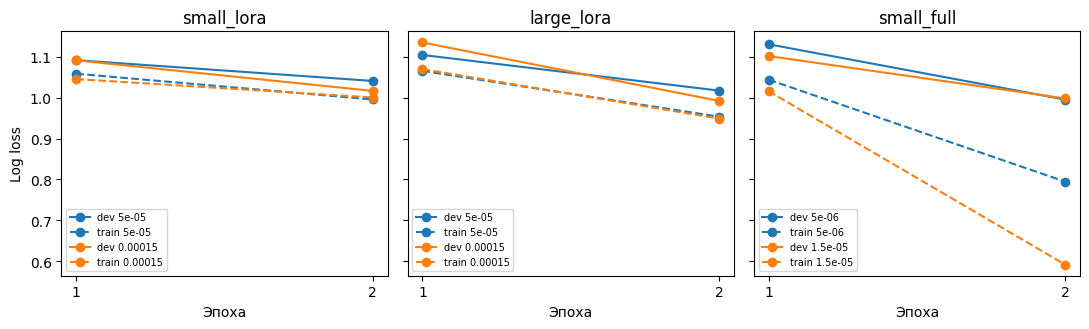

In [6]:
curves = pd.concat([pd.read_csv(qout/(m+"_curve.csv")).assign(model=m) for m in names[2:]])
print(curves[["model","lr","epoch","train_loss","dev_loss"]].round(6).to_string(index=False))
fig, axes = plt.subplots(1,3,figsize=(11,3.4),sharey=True)
for ax, name in zip(axes, names[2:]):
    for lr,rows in curves.loc[curves.model==name].groupby("lr"):
        line, = ax.plot(rows.epoch, rows.dev_loss, "o-", label=f"dev {lr:g}")
        ax.plot(rows.epoch, rows.train_loss, "o--", color=line.get_color(), label=f"train {lr:g}")
    ax.set(title=name, xlabel="Эпоха",xticks=[1,2])
    ax.legend(fontsize=7)
axes[0].set_ylabel("Log loss")
fig.tight_layout()
fig.savefig(qout/"curves.png",dpi=130)
plt.show()

На основных 717 парах Qwen3-4B с LoRA и полный файнтюн 1.7B обошли TF-IDF по log loss. У 4B получилось 1,0009, у полного 1.7B 1,0012, у TF-IDF на том же train 1,0801. У 1.7B с LoRA тоже ниже, 1,0320, но интервал разницы с этим TF-IDF включает ноль.

При одном размере 1.7B полное обучение дало выигрыш относительно LoRA в 0,0308. При увеличении модели с 1.7B до 4B с той же LoRA оценка улучшилась на 0,0312, но интервал включает ноль. На прежних 512 парах самый низкий log loss у 4B с LoRA, 0,9353.

После загрузки чекпоинтов все три модели повторили свои 1229 решений. Для 1.7B с LoRA пришлось повторить финальные две эпохи после сбоя сохранения. Взяли те же параметры и seed из первого подбора.

In [7]:
import mlflow
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("preferences-hw2")
with mlflow.start_run(run_name="Qwen3 и TF-IDF") as tracked:
    mlflow.log_params(dict(train=5352,inner_train=4282,inner_validation=1070,seed=42,effective_batch=64))
    for name in names[2:]:
        cfg = json.loads((qout/(name+".json")).read_text())
        for k in ["lr","epochs","revision","trainable_params"]:
            mlflow.log_param(name+"."+k,cfg[k])
    for row in scores.itertuples():
        mlflow.log_metrics({f"{row.model}.{row.rows}.loss":row.log_loss, f"{row.model}.{row.rows}.accuracy":row.accuracy})
    for (name,lr), df in curves.groupby(["model","lr"]):
        for row in df.itertuples():
            mlflow.log_metrics({f"{name}.{lr:g}.train":row.train_loss,f"{name}.{lr:g}.dev":row.dev_loss},step=row.epoch)
    for file in sorted(qout.iterdir()):
        if file.suffix in [".csv",".json",".md",".png"] and file.name!="tracking.json":
            mlflow.log_artifact(str(file))
    print("MLflow",tracked.info.run_id)

MLflow bbe7492df4104a7c86a1bd611b99b6ad


## Повтор эксперимента

Выше все числа считаются из сохраненных прогнозов. Ячейки ниже нужны для нового запуска.

### Дообучение PairJudge

Нужна выборка artifacts/hw2-input из первого ноутбука. Для адаптера проверяем одну и две эпохи.

In [ ]:
%pip install torch==2.8.0 transformers==4.57.6 huggingface-hub==0.36.2 pairjudge==0.3.0 onnxruntime==1.23.2 sentencepiece==0.2.1 pandas==2.3.3

In [ ]:
%pip install peft==0.18.0 accelerate==1.12.0 networkx==3.4.2

In [ ]:
from experiments.epochs import run_models

run_models(["pair"])

### Обучение Qwen и TF-IDF

Для отдельного запуска Qwen начните со свежего ядра с установленными библиотеками. Далее нужны только подготовленные данные и номера групп.

In [ ]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

bundle = Path("artifacts/hw2-input")
qout = Path("experiments/reports/hw2/qwen")
qout.mkdir(parents=True, exist_ok=True)
train_all = pd.read_json(bundle / "train.jsonl", lines=True, dtype={"id":str}).set_index("id")
valid_all = pd.read_json(bundle / "valid.jsonl", lines=True, dtype={"id":str}).set_index("id")
groups = pd.read_csv("experiments/reports/hw2/encoder_pairjudge_tuning/train_groups.csv", dtype={"id":str}).set_index("id").loc[train_all.index]
split = StratifiedGroupKFold(5, shuffle=True, random_state=42)
_, dev = next(split.split(train_all, train_all.target, groups.component))
train = train_all.loc[~groups.pair_known]
inner_dev = np.flatnonzero(train.index.isin(train_all.index[dev]))
inner_fit = np.flatnonzero(~train.index.isin(train_all.index[dev]))
assert (len(inner_fit),len(inner_dev)) == (4282,1070)
assert not set(groups.loc[train.index[inner_fit],"component"]) & set(groups.loc[train.index[inner_dev],"component"])

In [ ]:
audit = pd.read_csv(bundle / "split_audit.csv", dtype={"id":str}).set_index("id")
study = audit.loc[audit.text & ~audit.connected_to_train & ~audit.published_component, ["component","judge_panel"]].copy()
study["order"] = [hashlib.sha256(("42|"+i).encode()).hexdigest() for i in study.index]
study = study.sort_values("order").drop_duplicates("component").drop(columns="order")
previous = pd.read_csv(bundle / "judge_ids.csv",dtype={"id":str}).id
assert set(study.index[study.judge_panel]) == set(previous)
assert len(study) == 1229 and (~study.judge_panel).sum() == 717
assert not set(study.component) & set(groups.component)
test = valid_all.loc[study.index]
print("Обучение", len(train), "новые группы", (~study.judge_panel).sum(), "старые", study.judge_panel.sum())

Обучение 5352 новые группы 717 старые 512


In [ ]:
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

columns = ["prompt","response_a","response_b"]
texts = train[columns].map("\n".join)
vocab = TfidfVectorizer(ngram_range=(1,2), max_features=20000, min_df=3, sublinear_tf=True, dtype=np.float32)
vocab.fit(pd.concat([texts[c] for c in columns]))
def tfidf_features(frame):
    return sparse.hstack([vocab.transform(frame[c]) for c in columns], format="csr")
with threadpool_limits(limits=3):
    classifier = LogisticRegression(C=1., solver="lbfgs", max_iter=500, tol=.0001)
    classifier.fit(tfidf_features(texts), train.target)
    probs = classifier.predict_proba(tfidf_features(test[columns].map("\n".join)))
assert classifier.classes_.tolist() == [0,1,2]
pd.DataFrame(probs,index=test.index,columns=["A","B","tie"]).to_csv(qout/"tfidf_matched.csv")
original_lr = pd.read_csv(bundle/"matched_tfidf.csv",dtype={"id":str}).set_index("id").loc[test.index]
original_lr.to_csv(qout/"tfidf_incumbent.csv")
study.assign(target=test.target).to_csv(qout/"panel.csv")
print("TF-IDF",len(train),"обучающих пар,",len(test),"прогнозов")

TF-IDF 5352 обучающих пар, 1229 прогнозов


Qwen видит начало запроса и обоих ответов, TF-IDF использует текст целиком. Параметры Qwen выбираем по 1070 парам внутри train. Обучение запускаем на GPU, веса сохраняем в `artifacts/qwen-checkpoints/`.

In [ ]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
import gc
import time
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, set_seed
from peft import LoraConfig, get_peft_model

torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
sources = {"small": ("Qwen/Qwen3-1.7B","70d244cc86ccca08cf5af4e1e306ecf908b1ad5e"),
           "large": ("Qwen/Qwen3-4B","1cfa9a7208912126459214e8b04321603b3df60c")}
modes = {"small_lora":"small", "large_lora":"large", "small_full":"small"}
classes = ["A","B","tie"]
rates = {"lora":[5e-5,1.5e-4],"full":[5e-6,1.5e-5]}
print(torch.cuda.get_device_name(), torch.__version__)

NVIDIA H100 80GB HBM3 2.8.0+cu128


In [ ]:
def encode(frame, tokenizer):
    texts = frame[["prompt","response_a","response_b"]].map("\n".join)
    headers = [tokenizer.encode(t, add_special_tokens=False) for t in
               ("Question:\n", "\nAnswer A:\n", "\nAnswer B:\n", "\nPreference:")]
    parts = [tokenizer(texts[c].tolist(), add_special_tokens=False, truncation=True, max_length=n).input_ids
             for c,n in zip(texts, [96,192,192])]
    rows = [headers[0]+q+headers[1]+a+headers[2]+b+headers[3] for q,a,b in zip(*parts)]
    assert max(map(len,rows)) <= 512 and all(s[-1]!=tokenizer.pad_token_id for s in rows)
    return rows

In [ ]:
def new_classifier(mode, pad_id):
    set_seed(42)
    repo, revision = sources[modes[mode]]
    full = mode == "small_full"
    net = AutoModelForSequenceClassification.from_pretrained(repo, revision=revision, num_labels=3,
              dtype=torch.float32 if full else torch.bfloat16, attn_implementation="sdpa",
              id2label=dict(enumerate(classes)), label2id={v:i for i,v in enumerate(classes)},
              use_safetensors=True, pad_token_id=pad_id)
    net.config.use_cache = False
    initial = torch.empty(net.score.weight.shape, dtype=torch.float32)
    initial.normal_(std=net.config.initializer_range, generator=torch.Generator().manual_seed(42))
    with torch.no_grad():
        net.score.weight.copy_(initial.to(torch.bfloat16))

    if not full:
        settings = LoraConfig(task_type="SEQ_CLS", r=16, lora_alpha=32, lora_dropout=0.,
                              target_modules=["q_proj","v_proj"], modules_to_save=["score"])
        net = get_peft_model(net, settings)
        for param in net.parameters():
            if param.requires_grad:
                param.data = param.data.float()
    assert full == all(p.requires_grad for p in net.parameters())
    return net.cuda()

In [ ]:
def inputs(rows, ids, pad):
    seq = [rows[i] for i in ids]
    width = (max(map(len,seq))+7)//8*8
    tokens = np.full((len(seq),width), pad, dtype=np.int64)
    mask = np.zeros_like(tokens)
    for i,s in enumerate(seq):
        tokens[i,:len(s)] = s
        mask[i,:len(s)] = 1
    return {"input_ids":torch.from_numpy(tokens).cuda(), "attention_mask":torch.from_numpy(mask).cuda()}

@torch.inference_mode()
def predict_qwen(net, rows, ids, pad):
    net.eval()
    order = sorted(range(len(ids)), key=lambda i: len(rows[ids[i]]))
    p = np.empty((len(ids),3))
    for start in range(0,len(ids),16):
        loc = order[start:start+16]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = net(**inputs(rows,ids[loc],pad)).logits
        p[loc] = logits.float().softmax(-1).cpu().numpy()
    p /= p.sum(1,keepdims=True)
    assert np.isfinite(p).all() and (p>=0).all()
    return p

In [ ]:
def one_epoch(net, opt, rows, y, ids, pad, epoch):
    net.train()
    shuffled = np.random.default_rng(42+epoch).permutation(ids)
    for offset in range(0,len(ids),64):
        block = sorted(shuffled[offset:offset+64], key=lambda i:len(rows[i]))
        opt.zero_grad(set_to_none=True)
        for j in range(0,len(block),8):
            idx = block[j:j+8]
            batch = inputs(rows,idx,pad)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits = net(**batch).logits
                loss = torch.nn.functional.cross_entropy(logits.float(),torch.as_tensor(y[idx],device="cuda"),reduction="sum")/len(block)
            loss.backward()
        torch.nn.utils.clip_grad_norm_([p for p in net.parameters() if p.requires_grad],1.)
        opt.step()
        if (offset + len(block)) % 2048 == 0:
            print("Обработано",offset + len(block),"из",len(ids),flush=True)

def adam(net, lr):
    return torch.optim.AdamW([p for p in net.parameters() if p.requires_grad],lr=lr,weight_decay=.01,fused=True)

In [ ]:
from sklearn.metrics import log_loss
def tune(mode, rows, y, pad):
    history = []
    for lr in rates["full" if mode=="small_full" else "lora"]:
        net = new_classifier(mode,pad)
        opt = adam(net,lr)
        for epoch in (1,2):
            t = time.perf_counter()
            one_epoch(net,opt,rows,y,inner_fit,pad,epoch)
            record = {"lr":lr,"epoch":epoch}
            for split,ix in [("train",inner_fit),("dev",inner_dev)]:
                record[split+"_loss"] = log_loss(y[ix],predict_qwen(net,rows,ix,pad),labels=[0,1,2])
            record["seconds"] = time.perf_counter()-t
            history.append(record)
            pd.DataFrame(history).to_csv(qout/(mode+"_curve.csv"),index=False)
            print(mode,lr,epoch,round(record["train_loss"],5),round(record["dev_loss"],5),flush=True)
        del net,opt
        gc.collect()
        torch.cuda.empty_cache()
    return pd.DataFrame(history).sort_values(["dev_loss","epoch","lr"]).iloc[0]

In [ ]:
def fit_qwen(mode):
    repo,rev = sources[modes[mode]]
    tok = AutoTokenizer.from_pretrained(repo,revision=rev)
    train_rows, test_rows = encode(train,tok), encode(test,tok)
    y = train.target.to_numpy(dtype=np.int64)
    choice = tune(mode,train_rows,y,tok.pad_token_id)
    lr, epochs = float(choice.lr), int(choice.epoch)
    print(mode,"выбор",lr,epochs,flush=True)
    net = new_classifier(mode,tok.pad_token_id)
    opt = adam(net,lr)
    params = sum(p.numel() for p in net.parameters() if p.requires_grad)
    ids = np.arange(len(train))
    for epoch in range(1,epochs+1):
        one_epoch(net,opt,train_rows,y,ids,tok.pad_token_id,epoch)
    result = predict_qwen(net,test_rows,np.arange(len(test)),tok.pad_token_id)
    checkpoint = Path("artifacts/qwen-checkpoints") / mode
    checkpoint.mkdir(parents=True, exist_ok=True)
    (checkpoint/"README.md").write_text(f"# {repo} для сравнения двух ответов\n\n{mode}, {len(train)} обучающих пар. Классы A, B и ничья.\n")
    net.save_pretrained(checkpoint, safe_serialization=True)
    tok.save_pretrained(checkpoint)
    pd.DataFrame(result,index=test.index,columns=classes).to_csv(qout/(mode+".csv"))
    cfg = dict(model=repo,revision=rev,mode=mode,lr=lr,epochs=epochs,trainable_params=params,train_rows=len(train),
               torch=str(torch.__version__),gpu=torch.cuda.get_device_name(),seed=42,effective_batch=64,micro_batch=8)
    (qout/(mode+".json")).write_text(json.dumps(cfg,indent=2)+"\n")
    print(mode,"сохранено",len(result),flush=True)

In [ ]:
for mode in modes:
    fit_qwen(mode)
    gc.collect()
    torch.cuda.empty_cache()

Обработано 2048 из 4282
Обработано 4096 из 4282
small_lora 5e-05 1 1.05837 1.09152
Обработано 2048 из 4282
Обработано 4096 из 4282
small_lora 5e-05 2 0.99543 1.04073
Обработано 2048 из 4282
Обработано 4096 из 4282
small_lora 0.00015 1 1.04529 1.09113
Обработано 2048 из 4282
Обработано 4096 из 4282
small_lora 0.00015 2 1.00026 1.0163
small_lora выбор 0.00015 2
Обработано 2048 из 5352
Обработано 4096 из 5352
Обработано 2048 из 5352
Обработано 4096 из 5352
small_lora сохранено 1229
Обработано 2048 из 4282
Обработано 4096 из 4282
large_lora 5e-05 1 1.06532 1.10426
Обработано 2048 из 4282
Обработано 4096 из 4282
large_lora 5e-05 2 0.95349 1.01714
Обработано 2048 из 4282
Обработано 4096 из 4282
large_lora 0.00015 1 1.06963 1.13484
Обработано 2048 из 4282
Обработано 4096 из 4282
large_lora 0.00015 2 0.94873 0.99199
large_lora выбор 0.00015 2
Обработано 2048 из 5352
Обработано 4096 из 5352
Обработано 2048 из 5352
Обработано 4096 из 5352
large_lora сохранено 1229
Обработано 2048 из 4282
Обработ

После обучения вернитесь к первым разделам ноутбуков, чтобы пересчитать таблицы и интервалы по новым прогнозам.